<a href="https://colab.research.google.com/github/vikramsimha2510/VLM/blob/main/NITPY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!git clone https://github.com/vikramsimha2510/VLM.git

Cloning into 'VLM'...
remote: Enumerating objects: 180, done.
remote: Counting objects: 100% (180/180), done.
remote: Compressing objects: 100% (176/176), done.
remote: Total 180 (delta 16), reused 154 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (180/180), 8.41 MiB | 21.43 MiB/s, done.
Resolving deltas: 100% (16/16), done.


In [15]:
%cd /content/VLM

/content/VLM


In [16]:
# pip install torch open_clip_torch scikit-learn pandas matplotlib pillow
import os, glob, time, socket
import numpy as np, pandas as pd, torch, open_clip
from PIL import Image
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             confusion_matrix, silhouette_score, adjusted_rand_score)

# Force IPv4 (same fix as your other scripts)
_orig = socket.getaddrinfo
socket.getaddrinfo = lambda h, p, f=0, t=0, pr=0, fl=0: _orig(h, p, socket.AF_INET, t, pr, fl)

# ---------------- CONFIG ----------------
NORMAL_DIR = "DATASETS/Normal_Urban"      # change to DATASETS/Normal if you renamed it
SAT_DIR    = "DATASETS/Satellite"
OUT_DIR    = "outputs"
SEED       = 42
os.makedirs(OUT_DIR, exist_ok=True)

NORMAL_PROMPTS = ["a photo taken from the ground level",
                  "a street-level photograph of a city",
                  "a close-up photo of a shop, car or building",
                  "a normal everyday photograph"]
SAT_PROMPTS    = ["a satellite image",
                  "an aerial view from above",
                  "a remote sensing image of a city",
                  "a top-down overhead view of buildings and roads"]

# ---------------- 1. BUILD LABELS ----------------
rows = []
for typ, d in [("normal", NORMAL_DIR), ("satellite", SAT_DIR)]:
    for p in sorted(glob.glob(os.path.join(d, "**", "*"), recursive=True)):
        if p.lower().endswith((".jpg", ".jpeg", ".png")):
            name = os.path.basename(p)
            rows.append({"path": p, "image": name, "type": typ,
                         "category": name.rsplit("_", 1)[0]})
df = pd.DataFrame(rows)
y = (df["type"] == "satellite").astype(int).values       # 0 = normal, 1 = satellite
df.drop(columns="path").to_csv(f"{OUT_DIR}/labels.csv", index=False)
print(df["type"].value_counts().to_string(), "\n")

# ---------------- 2. CLIP EMBEDDINGS ----------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
tokenizer = open_clip.get_tokenizer("ViT-B-32")
model = model.to(device).eval()
if device == "cuda":
    model = model.half()
    torch.cuda.reset_peak_memory_stats()

t0, feats = time.time(), []
with torch.no_grad():
    for i in range(0, len(df), 16):
        x = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in df["path"][i:i+16]]).to(device)
        if device == "cuda":
            x = x.half()
        f = model.encode_image(x)
        f = f / f.norm(dim=-1, keepdim=True)
        feats.append(f.float().cpu().numpy())
X = np.concatenate(feats)
embed_time = (time.time() - t0) / len(df)
vram = torch.cuda.max_memory_allocated() / 1e6 if device == "cuda" else 0
np.save(f"{OUT_DIR}/clip_embeddings.npy", X)
print(f"Embedding: {embed_time*1000:.1f} ms/image, peak VRAM {vram:.0f} MB\n")

# ---------------- 3. ZERO-SHOT ROUTER ----------------
def text_emb(prompts):
    with torch.no_grad():
        t = model.encode_text(tokenizer(prompts).to(device))
        t = t / t.norm(dim=-1, keepdim=True)
        t = t.float().mean(0)
        return (t / t.norm()).cpu().numpy()

T = np.stack([text_emb(NORMAL_PROMPTS), text_emb(SAT_PROMPTS)])
logits = 100 * X @ T.T
e = np.exp(logits - logits.max(1, keepdims=True))
probs = e / e.sum(1, keepdims=True)
zs_pred, zs_score = logits.argmax(1), probs[:, 1]

def metrics(y_true, pred, score):
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    return {"accuracy": accuracy_score(y_true, pred), "precision": p, "recall": r,
            "f1": f, "roc_auc": roc_auc_score(y_true, score)}

results = {"Zero-shot CLIP": metrics(y, zs_pred, zs_score)}
preds = {"Zero-shot CLIP": zs_pred}

# ---------------- 4. SUPERVISED ROUTERS (5-fold CV) ----------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM (linear)":        make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "kNN (k=3)":           KNeighborsClassifier(n_neighbors=3, metric="cosine"),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_std = {}
for name, m in models.items():
    cv = cross_validate(m, X, y, cv=skf, scoring=scoring)
    results[name] = {k: cv[f"test_{k}"].mean() for k in scoring}
    cv_std[name] = {k: cv[f"test_{k}"].std() for k in scoring}
    preds[name] = cross_val_predict(m, X, y, cv=skf)

table = pd.DataFrame(results).T
table_str = table.copy().astype(object)
for name in table.index:
    for k in scoring:
        sd = cv_std.get(name, {}).get(k)
        table_str.loc[name, k] = f"{table.loc[name, k]:.3f}" + (f" ± {sd:.3f}" if sd is not None else "")
table_str.to_csv(f"{OUT_DIR}/router_results.csv")
print("ROUTER RESULTS (supervised = 5-fold CV mean ± std)")
print(table_str.to_string(), "\n")

# ---------------- 5. CLUSTERING CHECK ----------------
km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X)
print(f"K-Means (k=2): silhouette = {silhouette_score(X, km.labels_):.3f}, "
      f"ARI vs true type = {adjusted_rand_score(y, km.labels_):.3f}\n")

# ---------------- 6. ERROR ANALYSIS ----------------
df["zs_pred"] = np.where(zs_pred == 1, "satellite", "normal")
df["zs_sat_prob"] = zs_score.round(3)
per_cat = (df.assign(correct=(df["zs_pred"] == df["type"]))
             .groupby(["type", "category"])["correct"].mean().round(2))
print("Zero-shot accuracy per category:\n", per_cat.to_string(), "\n")
wrong = df[df["zs_pred"] != df["type"]][["image", "type", "zs_pred", "zs_sat_prob"]]
wrong.to_csv(f"{OUT_DIR}/router_misclassified.csv", index=False)
print("Zero-shot misrouted images:\n", wrong.to_string(index=False) if len(wrong) else "none")

# ---------------- 7. CONFUSION MATRICES ----------------
fig, axes = plt.subplots(1, len(preds), figsize=(4 * len(preds), 4))
for ax, (name, pr) in zip(axes, preds.items()):
    cm = confusion_matrix(y, pr)
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "satellite"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "satellite"])
    ax.set_title(name, fontsize=10); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/router_confusion.png", dpi=150)
print(f"\nSaved results to ./{OUT_DIR}/")

type
satellite    70
normal       30 

Device: cuda


/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Embedding: 4.4 ms/image, peak VRAM 9260 MB

ROUTER RESULTS (supervised = 5-fold CV mean ± std)
                          accuracy      precision         recall             f1        roc_auc
Zero-shot CLIP               1.000          1.000          1.000          1.000          1.000
Logistic Regression  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
SVM (linear)         1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
SVM (RBF)            1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000  1.000 ± 0.000
kNN (k=3)            0.840 ± 0.037  0.816 ± 0.036  1.000 ± 0.000  0.898 ± 0.022  0.833 ± 0.091 

K-Means (k=2): silhouette = 0.182, ARI vs true type = 0.879

Zero-shot accuracy per category:
 type       category         
normal     building             1.0
           cafe                 1.0
           cars                 1.0
           house                1.0
           road                 1.0
           supermarket       

Satellite images: 70
Normal urban images: 30
Total images: 100


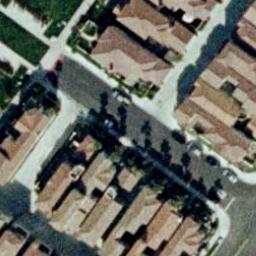

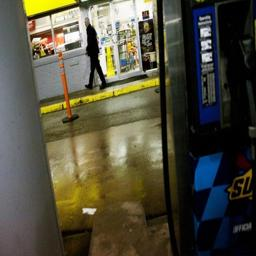

In [17]:

from pathlib import Path
from PIL import Image
from IPython.display import display

# Actual GitHub dataset locations
satellite_path = Path("/content/VLM/DATASETS/Satellite")
normal_path = Path("/content/VLM/DATASETS/Normal_Urban")

# Find images
satellite_images = list(satellite_path.rglob("*.jpg"))
normal_images = list(normal_path.rglob("*.jpg"))

print("Satellite images:", len(satellite_images))
print("Normal urban images:", len(normal_images))
print("Total images:", len(satellite_images) + len(normal_images))

# Display one satellite image
if satellite_images:
    display(Image.open(satellite_images[0]))

# Display one normal urban image
if normal_images:
    display(Image.open(normal_images[0]))


In [18]:
from collections import Counter

satellite_counts = Counter(
    image.stem.rsplit("_", 1)[0]
    for image in satellite_images
)

normal_counts = Counter(
    image.stem.rsplit("_", 1)[0]
    for image in normal_images
)

print("SATELLITE CATEGORY DISTRIBUTION")
for category, count in sorted(satellite_counts.items()):
    print(category, ":", count)

print("\nNORMAL URBAN CATEGORY DISTRIBUTION")
for category, count in sorted(normal_counts.items()):
    print(category, ":", count)

SATELLITE CATEGORY DISTRIBUTION
buildings : 10
denseresidential : 10
forest : 10
freeway : 10
golfcourse : 10
intersection : 10
mediumresidential : 10

NORMAL URBAN CATEGORY DISTRIBUTION
building : 5
cafe : 5
cars : 5
house : 5
road : 5
supermarket : 5


In [19]:

from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

# Correct category extraction from filenames
satellite_counts = Counter(
    img.stem.rsplit("_", 1)[0]
    for img in satellite_images
)

normal_counts = Counter(
    img.stem.rsplit("_", 1)[0]
    for img in normal_images
)

print("SATELLITE CATEGORY DISTRIBUTION")
for category, count in sorted(satellite_counts.items()):
    print(f"{category}: {count}")

print("\nNORMAL URBAN CATEGORY DISTRIBUTION")
for category, count in sorted(normal_counts.items()):
    print(f"{category}: {count}")

# Check image integrity and dimensions
all_images = satellite_images + normal_images
corrupted = []
dimensions = Counter()

for path in all_images:
    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            dimensions[img.size] += 1

    except Exception as e:
        corrupted.append((path.name, str(e)))

print("\nIMAGE QUALITY CHECK")
print("Total images:", len(all_images))
print("Corrupted images:", len(corrupted))
print("Image dimensions:", dimensions)

if corrupted:
    print("\nCorrupted files:")
    for name, error in corrupted:
        print(name, error)


SATELLITE CATEGORY DISTRIBUTION
buildings: 10
denseresidential: 10
forest: 10
freeway: 10
golfcourse: 10
intersection: 10
mediumresidential: 10

NORMAL URBAN CATEGORY DISTRIBUTION
building: 5
cafe: 5
cars: 5
house: 5
road: 5
supermarket: 5

IMAGE QUALITY CHECK
Total images: 100
Corrupted images: 0
Image dimensions: Counter({(256, 256): 99, (256, 251): 1})


In [20]:

import matplotlib.pyplot as plt
from PIL import Image

sample_images = satellite_images[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, path in zip(axes.flat, sample_images):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


File: buildings_01.jpg | size: (256, 256) | true type: satellite


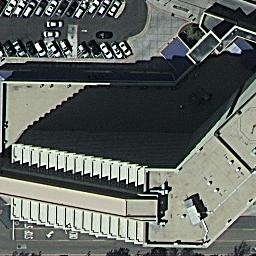

In [21]:
import random
from pathlib import Path
from PIL import Image
from IPython.display import display

DATA_ROOT = Path("/content/VLM/DATASETS")
EXTS = {".jpg", ".jpeg", ".png", ".webp"}

def load_input(path=None, seed=None):
    """path=None -> random image from the dataset.
       path='any/image.jpg' -> that image (works on any image)."""
    if path is None:
        files = [p for p in DATA_ROOT.rglob("*") if p.suffix.lower() in EXTS]
        path = random.Random(seed).choice(files)
    path = Path(path)
    image = Image.open(path).convert("RGB")
    # ground truth is only known for dataset images
    true_type = None
    if str(DATA_ROOT) in str(path):
        true_type = "satellite" if "Satellite" in path.parts else "normal"
    return path, image, true_type

# ---- choose ONE ----
image_path, image, true_type = load_input()                      # random from dataset
# image_path, image, true_type = load_input("/content/my_image.jpg")   # your own image

# Optional: upload your own image in Colab
# from google.colab import files
# up = files.upload()
# image_path, image, true_type = load_input(list(up)[0])

print(f"File: {image_path.name} | size: {image.size} | true type: {true_type}")
display(image)

In [22]:
%pip install -q open_clip_torch

import torch, open_clip

device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
clip_tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")
clip_model = clip_model.to(device).eval()

NORMAL_PROMPTS = ["a photo taken from the ground level",
                  "a street-level photograph of a city",
                  "a close-up photo of a shop, car or building",
                  "a normal everyday photograph"]
SAT_PROMPTS    = ["a satellite image",
                  "an aerial view from above",
                  "a remote sensing image of a city",
                  "a top-down overhead view of buildings and roads"]

def _text_emb(prompts):
    with torch.no_grad():
        t = clip_model.encode_text(clip_tokenizer(prompts).to(device))
        t = t / t.norm(dim=-1, keepdim=True)
        t = t.mean(0)
        return t / t.norm()

TEXT = torch.stack([_text_emb(NORMAL_PROMPTS), _text_emb(SAT_PROMPTS)])   # [normal, satellite]

def classify_image(image, low_conf=0.75):
    """Zero-shot router: needs no training, so it works on any image."""
    x = clip_preprocess(image).unsqueeze(0).to(device)
    with torch.no_grad():
        f = clip_model.encode_image(x)
        f = f / f.norm(dim=-1, keepdim=True)
        probs = (100 * f @ TEXT.T).softmax(dim=-1)[0].cpu().tolist()
    p_normal, p_sat = probs
    label = "satellite" if p_sat > p_normal else "normal"
    conf = max(p_normal, p_sat)
    return {"label": label, "p_normal": round(p_normal, 3), "p_satellite": round(p_sat, 3),
            "confidence": round(conf, 3), "low_confidence": conf < low_conf}

result = classify_image(image)
print("Predicted type :", result["label"])
print("Probabilities  : normal =", result["p_normal"], "| satellite =", result["p_satellite"])
if result["low_confidence"]:
    print("Warning: low confidence, this image may be neither a clear photo nor a satellite view")
if true_type:
    print("True type      :", true_type, "->", "correct" if result["label"] == true_type else "WRONG")

Predicted type : satellite
Probabilities  : normal = 0.002 | satellite = 0.998
True type      : satellite -> correct


In [23]:
import time, torch, pandas as pd
from transformers import BlipProcessor, BlipForConditionalGeneration

NORMAL_CAPTIONERS = {
    "BLIP-base":  "Salesforce/blip-image-captioning-base",
    "BLIP-large": "Salesforce/blip-image-captioning-large",
}
_cap_cache = {}
dtype = torch.float16 if device == "cuda" else torch.float32

def clip_match(image, text):
    """CLIP image-text cosine similarity (higher = caption matches image better)."""
    x = clip_preprocess(image).unsqueeze(0).to(device)
    t = clip_tokenizer([text]).to(device)
    with torch.no_grad():
        fi = clip_model.encode_image(x); fi = fi / fi.norm(dim=-1, keepdim=True)
        ft = clip_model.encode_text(t);  ft = ft / ft.norm(dim=-1, keepdim=True)
    return round((fi @ ft.T).item(), 4)

def caption_normal(image):
    rows = []
    for name, repo in NORMAL_CAPTIONERS.items():
        if name not in _cap_cache:
            proc = BlipProcessor.from_pretrained(repo)
            model = BlipForConditionalGeneration.from_pretrained(repo, torch_dtype=dtype).to(device).eval()
            _cap_cache[name] = (proc, model)
        proc, model = _cap_cache[name]
        inputs = proc(images=image, return_tensors="pt").to(device, dtype)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=40, num_beams=3)
        if device == "cuda": torch.cuda.synchronize()
        caption = proc.decode(out[0], skip_special_tokens=True).strip()
        rows.append({"model": name, "caption": caption,
                     "clip_match": clip_match(image, caption),
                     "seconds": round(time.time() - t0, 2)})
    return pd.DataFrame(rows)

FORCE = False   # True = run normal captioners even on a satellite image (for the general-vs-specialist comparison)

if result["label"] == "normal" or FORCE:
    pd.set_option("display.max_colwidth", None)
    normal_caps = caption_normal(image)
    display(normal_caps)
else:
    print("Predicted satellite -> use the satellite branch (next cells)")

Predicted satellite -> use the satellite branch (next cells)


In [24]:
import time, torch, pandas as pd
from transformers import BlipProcessor, BlipForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
_sat_cache = globals().get("_sat_cache", {})

SAT_CAPTIONERS = {   # name: (model repo, processor repo)
    "RSICD-BLIP (specialist)": ("Gurveer05/blip-image-captioning-base-rscid-finetuned",
                                "Salesforce/blip-image-captioning-base"),
    "BLIP-base (general)":     ("Salesforce/blip-image-captioning-base",
                                "Salesforce/blip-image-captioning-base"),
    "BLIP-large (general)":    ("Salesforce/blip-image-captioning-large",
                                "Salesforce/blip-image-captioning-large"),
}

def caption_satellite(image):
    rows = []
    for name, (model_repo, proc_repo) in SAT_CAPTIONERS.items():
        if name not in _sat_cache:
            proc = BlipProcessor.from_pretrained(proc_repo)
            model = BlipForConditionalGeneration.from_pretrained(model_repo, torch_dtype=dtype).to(device).eval()
            _sat_cache[name] = (proc, model)
        proc, model = _sat_cache[name]
        inputs = proc(images=image, return_tensors="pt").to(device, dtype)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=40, num_beams=3)
        if device == "cuda": torch.cuda.synchronize()
        rows.append({"model": name,
                     "caption": proc.decode(out[0], skip_special_tokens=True).strip(),
                     "seconds": round(time.time() - t0, 2)})
    return pd.DataFrame(rows)

FORCE_SAT = False   # True = run even if the router said "normal"

if result["label"] == "satellite" or FORCE_SAT:
    pd.set_option("display.max_colwidth", None)
    sat_caps = caption_satellite(image)
    display(sat_caps)
else:
    print("Predicted normal -> use the normal branch (Cell 3)")

,model,caption,seconds
0,RSICD-BLIP (specialist),some cars are parked in front of a church.,0.30
1,BLIP-base (general),an aerial view of a parking lot with cars parked in the parking lot,0.65
2,BLIP-large (general),an aerial view of a parking lot with a lot of cars parked in it,0.57


In [25]:
import torch, open_clip
from huggingface_hub import hf_hub_download

# Official RemoteCLIP weights (OpenCLIP format); stored outside the repo folder
rc_path = hf_hub_download("chendelong/RemoteCLIP", "RemoteCLIP-ViT-B-32.pt", cache_dir="/content/checkpoints")
rc_model, _, rc_preprocess = open_clip.create_model_and_transforms("ViT-B-32")
rc_tokenizer = open_clip.get_tokenizer("ViT-B-32")
print(rc_model.load_state_dict(torch.load(rc_path, map_location="cpu")))
rc_model = rc_model.to(device).eval()

def sim(model, preprocess, tokenizer, image, texts):
    """cosine similarity between one image and a list of texts"""
    x = preprocess(image).unsqueeze(0).to(device)
    t = tokenizer(texts).to(device)
    with torch.no_grad():
        fi = model.encode_image(x); fi = fi / fi.norm(dim=-1, keepdim=True)
        ft = model.encode_text(t);  ft = ft / ft.norm(dim=-1, keepdim=True)
    return (fi @ ft.T)[0].cpu()

LANDUSE_TAGS = ["dense residential area", "medium density residential area", "buildings",
                "commercial buildings", "industrial area", "freeway or highway",
                "road intersection", "forest or trees", "golf course or open green space",
                "farmland", "water"]

def land_use_tags(image, top_k=3):
    sims = sim(rc_model, rc_preprocess, rc_tokenizer, image,
               [f"a satellite image of {t}" for t in LANDUSE_TAGS])
    probs = (100 * sims).softmax(dim=-1)
    top = probs.topk(top_k)
    return [(LANDUSE_TAGS[i], round(p.item(), 3)) for p, i in zip(top.values, top.indices)]

if result["label"] == "satellite" or FORCE_SAT:
    print("Top land-use tags:", land_use_tags(image))
    if true_type == "satellite":
        print("Dataset class (reference):", image_path.name.rsplit("_", 1)[0])
    if "sat_caps" in globals():
        sat_caps["clip_match"] = [round(sim(clip_model, clip_preprocess, clip_tokenizer, image, [c]).item(), 4)
                                  for c in sat_caps["caption"]]
        sat_caps["remoteclip_match"] = [round(sim(rc_model, rc_preprocess, rc_tokenizer, image, [c]).item(), 4)
                                        for c in sat_caps["caption"]]
        display(sat_caps)
else:
    print("Predicted normal -> satellite tagging skipped")

<All keys matched successfully>
Top land-use tags: [('buildings', 0.832), ('commercial buildings', 0.097), ('road intersection', 0.038)]
Dataset class (reference): buildings


,model,caption,seconds,clip_match,remoteclip_match
0,RSICD-BLIP (specialist),some cars are parked in front of a church.,0.30,0.2304,0.2786
1,BLIP-base (general),an aerial view of a parking lot with cars parked in the parking lot,0.65,0.3103,0.2891
2,BLIP-large (general),an aerial view of a parking lot with a lot of cars parked in it,0.57,0.2895,0.2960


In [26]:
import random, time, torch, pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# ---------------- CONFIG ----------------
N_PER_BRANCH = None       # images per branch; set to None to run all 100
SEED = 42
OUT = Path("/content/VLM/outputs"); OUT.mkdir(exist_ok=True)

# which caption counts as "the pipeline's output" for each routed branch
PIPELINE_MODEL = {"satellite": "RSICD-BLIP (specialist)", "normal": "BLIP-large"}

# dataset class -> expected RemoteCLIP land-use tag (satellite)
CLASS_TO_TAG = {"forest": "forest or trees", "golfcourse": "golf course or open green space",
                "denseresidential": "dense residential area", "mediumresidential": "medium density residential area",
                "buildings": "buildings", "freeway": "freeway or highway", "intersection": "road intersection"}

# simple keyword lists to check whether a caption mentions the right thing
KEYWORDS = {
    "forest": ["forest", "tree", "wood", "green"], "golfcourse": ["golf", "grass", "green", "field", "course"],
    "denseresidential": ["residential", "house", "building", "dense"], "mediumresidential": ["residential", "house", "building"],
    "buildings": ["building", "house", "roof"], "freeway": ["road", "freeway", "highway", "street", "bridge"],
    "intersection": ["intersection", "road", "crossing", "street"],
    "cars": ["car", "vehicle", "parking", "truck", "bus"], "road": ["road", "street", "highway", "intersection", "crosswalk"],
    "building": ["building", "skyscraper", "tower", "city", "office"], "house": ["house", "home", "residential", "building"],
    "supermarket": ["store", "shop", "market", "grocery", "supermarket", "fruit", "vegetable"],
    "cafe": ["cafe", "restaurant", "coffee", "table", "bar", "dining", "people"],
}

# ---------------- SAMPLE (stratified by class) ----------------
def sample_paths(n, seed=SEED):
    rng, out = random.Random(seed), []
    for sat in (False, True):
        files = sorted(p for p in DATA_ROOT.rglob("*")
                       if p.suffix.lower() in EXTS and (("Satellite" in p.parts) == sat))
        if n is None:
            out += files; continue
        by_cat = {}
        for p in files:
            by_cat.setdefault(p.name.rsplit("_", 1)[0], []).append(p)
        cats = list(by_cat); rng.shuffle(cats)
        chosen, i = [], 0
        while len(chosen) < n and i < 1000:
            pool = [p for p in by_cat[cats[i % len(cats)]] if p not in chosen]
            if pool: chosen.append(rng.choice(pool))
            i += 1
        out += chosen
    return out

paths = sample_paths(N_PER_BRANCH)
print(f"Running {len(paths)} images")

# warm-up so timings are fair (first call per model is slow)
_w = load_input(paths[0])[1]
caption_normal(_w); caption_satellite(_w)
if device == "cuda": torch.cuda.reset_peak_memory_stats()

# ---------------- RUN PIPELINE ----------------
rows_img, rows_cap = [], []
for p in tqdm(paths):
    image_path, image, true_type = load_input(p)
    category = image_path.name.rsplit("_", 1)[0]
    r = classify_image(image)
    branch = r["label"]

    row = {"image": image_path.name, "true_type": true_type, "category": category,
           "router_pred": branch, "p_satellite": r["p_satellite"], "router_correct": branch == true_type}

    if branch == "satellite":
        tags = land_use_tags(image, top_k=3)
        row["top_tags"] = "; ".join(f"{t}({s})" for t, s in tags)
        expected = CLASS_TO_TAG.get(category)
        if expected:
            row["tag_top1"] = tags[0][0] == expected
            row["tag_top3"] = expected in [t for t, _ in tags]
        caps = caption_satellite(image)
    else:
        caps = caption_normal(image).drop(columns=["clip_match"], errors="ignore")

    caps["clip_match"] = [round(sim(clip_model, clip_preprocess, clip_tokenizer, image, [c]).item(), 4) for c in caps["caption"]]
    caps["remoteclip_match"] = [round(sim(rc_model, rc_preprocess, rc_tokenizer, image, [c]).item(), 4) for c in caps["caption"]]
    kws = KEYWORDS.get(category, [])
    caps["keyword_hit"] = [any(k in c.lower() for k in kws) for c in caps["caption"]]
    caps["is_pipeline_output"] = caps["model"] == PIPELINE_MODEL[branch]
    for col, val in [("image", image_path.name), ("true_type", true_type), ("category", category), ("branch", branch)]:
        caps.insert(0, col, val)

    rows_img.append(row); rows_cap.append(caps)

img_df = pd.DataFrame(rows_img)
cap_df = pd.concat(rows_cap, ignore_index=True)

# ---------------- SAVE ----------------
img_df.to_csv(OUT / "batch_images.csv", index=False)
cap_df.to_csv(OUT / "batch_captions.csv", index=False)

# ---------------- SUMMARY ----------------
print("\nROUTER accuracy:", round(img_df["router_correct"].mean(), 3))
if "tag_top1" in img_df:
    t = img_df.dropna(subset=["tag_top1"])
    print(f"TAGS (satellite): top-1 = {t['tag_top1'].mean():.3f} | top-3 = {t['tag_top3'].mean():.3f} | n = {len(t)}")

summary = (cap_df.groupby(["branch", "model"])
           .agg(n=("image", "count"), clip_match=("clip_match", "mean"),
                remoteclip_match=("remoteclip_match", "mean"),
                keyword_hit=("keyword_hit", "mean"), seconds=("seconds", "mean"))
           .round(3))
summary.to_csv(OUT / "batch_summary.csv")
print("\nCAPTION SUMMARY (means):"); display(summary)

if device == "cuda":
    print(f"\nPeak VRAM: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")

pd.set_option("display.max_colwidth", None); pd.set_option("display.width", 250)
print("\nALL CAPTIONS:")
display(cap_df[["image", "branch", "model", "caption", "clip_match", "remoteclip_match", "keyword_hit"]])

Running 100 images


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/616 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]


ROUTER accuracy: 0.97
TAGS (satellite): top-1 = 0.843 | top-3 = 1.000 | n = 70

CAPTION SUMMARY (means):


n  clip_match  remoteclip_match  keyword_hit  seconds
branch    model                                                                          
normal    BLIP-base                27       0.274             0.277        0.852    0.561
          BLIP-large               27       0.280             0.283        0.815    0.754
satellite BLIP-base (general)      73       0.305             0.272        0.753    0.353
          BLIP-large (general)     73       0.304             0.277        0.822    0.460
          RSICD-BLIP (specialist)  73       0.266             0.269        0.849    0.426


Peak VRAM: 9.32 GB

ALL CAPTIONS:


,image,branch,model,caption,clip_match,remoteclip_match,keyword_hit
0,building_01.jpg,normal,BLIP-base,the sky is cloudy,0.2044,0.2483,False
1,building_01.jpg,normal,BLIP-large,there is a large building that has a lot of stairs in front of it,0.2500,0.2783,True
2,building_02.jpg,normal,BLIP-base,a red bus driving down a street next to tall buildings,0.2910,0.2886,True
3,building_02.jpg,normal,BLIP-large,there are many buses that are parked on the side of the road,0.2427,0.3170,False
4,building_03.jpg,satellite,RSICD-BLIP (specialist),two buildings are close to a park with some green trees and a swimming pool.,0.2414,0.2557,True
...,...,...,...,...,...,...,...
268,mediumresidential_09.jpg,satellite,BLIP-base (general),an aerial view of a street in a small town,0.2907,0.2786,False
269,mediumresidential_09.jpg,satellite,BLIP-large (general),an aerial view of a small town with a street and several buildings,0.2732,0.2880,True
270,mediumresidential_10.jpg,satellite,RSICD-BLIP (specialist),many green buildings and trees are located in an average residential area.,0.2905,0.2680,True
271,mediumresidential_10.jpg,satellite,BLIP-base (general),an aerial view of a neighborhood,0.3093,0.2634,False


In [27]:
import re, torch
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

if "qwen" not in globals():
    QWEN = "Qwen/Qwen2-VL-2B-Instruct"
    qwen = Qwen2VLForConditionalGeneration.from_pretrained(QWEN, torch_dtype=torch.float16, device_map="auto")
    qproc = AutoProcessor.from_pretrained(QWEN, min_pixels=256*28*28, max_pixels=512*28*28)

PROMPT = ("Describe this satellite image in one paragraph of 3 to 4 sentences. Cover the land use "
          "(residential, commercial, industrial, green space), the buildings, the roads, the vegetation, "
          "and how they are arranged relative to each other. Only describe what is visible.")

RS_VOCAB = ["building", "house", "residential", "commercial", "industrial", "road", "street", "highway",
            "freeway", "intersection", "crossing", "bridge", "parking lot", "car", "tree", "forest",
            "vegetation", "grass", "green space", "park", "golf course", "field", "farmland", "river",
            "water", "pond", "swimming pool", "playground", "runway", "open space", "lawn", "driveway"]

def paragraph_level(image):
    msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
    text = qproc.apply_chat_template(msgs, add_generation_prompt=True)
    inputs = qproc(text=[text], images=[image], return_tensors="pt").to(qwen.device)
    with torch.no_grad():
        out = qwen.generate(**inputs, max_new_tokens=150, do_sample=False)
    return qproc.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

def sentence_level(paragraph):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", paragraph) if s.strip()]

def keyword_level(paragraph, image, top_k=3):
    low = paragraph.lower()
    kws = [k for k in RS_VOCAB if re.search(rf"\b{k}s?\b", low)]
    kws += [t for t, _ in land_use_tags(image, top_k)]          # RemoteCLIP tags
    return list(dict.fromkeys(kws))

def hierarchical_caption(image):
    para = paragraph_level(image)
    sents = sentence_level(para)
    kws = keyword_level(para, image)
    rc = lambda texts: sim(rc_model, rc_preprocess, rc_tokenizer, image, texts)
    return {"paragraph": para, "sentences": sents, "keywords": kws,
            "score_paragraph": round(rc([para]).item(), 4),
            "score_sentence": round(rc(sents).mean().item(), 4),
            "score_keyword": round(rc([f"a satellite image of {k}" for k in kws]).mean().item(), 4)}

if result["label"] == "satellite" or FORCE_SAT:
    h = hierarchical_caption(image)
    print("PARAGRAPH:", h["paragraph"])
    print("\nSENTENCES:"); [print(" -", s) for s in h["sentences"]]
    print("\nKEYWORDS:", h["keywords"])
    print("\nRemoteCLIP match by level:", {k: v for k, v in h.items() if k.startswith("score")})
    if true_type == "satellite":
        print("Dataset class (reference):", image_path.name.rsplit("_", 1)[0])
else:
    print("Predicted normal -> hierarchy skipped")

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


PARAGRAPH: The satellite image depicts a residential area with a mix of houses and a few commercial buildings. The houses are primarily single-family homes, with some having swimming pools. The vegetation includes trees and shrubs, which are interspersed among the houses and roads. The roads are narrow and appear to be residential streets, with some having sidewalks. The overall arrangement of the buildings and vegetation suggests a suburban or semi-rural setting.

SENTENCES:
 - The satellite image depicts a residential area with a mix of houses and a few commercial buildings.
 - The houses are primarily single-family homes, with some having swimming pools.
 - The vegetation includes trees and shrubs, which are interspersed among the houses and roads.
 - The roads are narrow and appear to be residential streets, with some having sidewalks.
 - The overall arrangement of the buildings and vegetation suggests a suburban or semi-rural setting.

KEYWORDS: ['building', 'house', 'residential'